# VeriSight AI — Clean, Reproducible FaceForensics++ Baseline

**Purpose:** train and evaluate the first image/frame branch of VeriSight AI using the existing FaceForensics++ C23 200-video subset.

This notebook is deliberately linear. Run cells from top to bottom in a fresh Google Colab runtime with a GPU runtime selected.

## Fixed project decisions
- Dataset: existing `FaceForensics++_c23_200`
- Real label: `0`; Fake label: `1`
- Real videos: `original_sequences/youtube/c23/videos`
- Fake videos: `manipulated_sequences/Deepfakes/c23/videos`
- Backbone: ImageNet-pretrained EfficientNet-B0
- Input: RGB, 224 × 224
- Storage: Google Drive
- Split: source-identity-disjoint, approximately 70% / 15% / 15%
- Evaluation: frame-level diagnostics and **video-level primary metrics**
- No threshold tuning on the test set

**Important:** this is a frame-based video baseline, not yet a complete temporal or multimodal detector. It does not train the audio or temporal branches.

## 1. Select a GPU and mount Google Drive

In Colab, choose **Runtime → Change runtime type → T4 GPU** (or another available GPU). Then run this cell.

The mount logic avoids remounting when Drive is already available.

In [ ]:
from pathlib import Path
import os, sys, json, random, math, time, shutil, warnings
import numpy as np
import pandas as pd

DRIVE = Path("/content/drive")
MY_DRIVE = DRIVE / "MyDrive"

if MY_DRIVE.exists():
    print("Google Drive is already mounted.")
else:
    from google.colab import drive
    drive.mount("/content/drive")

assert MY_DRIVE.exists(), "Google Drive is not mounted. Mount it and rerun this cell."

STORAGE = MY_DRIVE / "VeriSight_AI_Storage"
VIDEO_ROOT = STORAGE / "datasets" / "video"
DATASET_ROOT = VIDEO_ROOT / "FaceForensics++_c23_200"

WORK_ROOT = STORAGE / "verisight_ffpp_baseline"
FRAME_ROOT = WORK_ROOT / "frames"
OUTPUT_ROOT = STORAGE / "models"
REPORT_ROOT = STORAGE / "reports"

for folder in [WORK_ROOT, FRAME_ROOT, OUTPUT_ROOT, REPORT_ROOT]:
    folder.mkdir(parents=True, exist_ok=True)

print("Dataset candidate:", DATASET_ROOT)
print("Working directory:", WORK_ROOT)
print("Model output directory:", OUTPUT_ROOT)

Mounted at /content/drive
Dataset candidate: /content/drive/MyDrive/VeriSight_AI_Storage/datasets/video/FaceForensics++_c23_200
Working directory: /content/drive/MyDrive/VeriSight_AI_Storage/verisight_ffpp_baseline
Model output directory: /content/drive/MyDrive/VeriSight_AI_Storage/models


## 2. Install and check dependencies

This notebook uses torchvision EfficientNet-B0, OpenCV for video decoding, and scikit-learn for metrics.

In [ ]:
%pip -q install --upgrade scikit-learn opencv-python-headless

import cv2
import torch
import torchvision
from torchvision import transforms, models
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("OpenCV:", cv2.__version__)
print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu130
Torchvision: 0.26.0+cu130
OpenCV: 4.14.0
Device: cuda
GPU: Tesla T4


## 3. Locate and validate the FaceForensics++ subset

Expected folder structure:

```text
FaceForensics++_c23_200/
├── original_sequences/youtube/c23/videos/*.mp4
└── manipulated_sequences/Deepfakes/c23/videos/*.mp4
```

The cell also searches under the configured video directory if the folder name differs. It will stop rather than silently use the wrong dataset.

In [ ]:
def find_dataset_root(search_root: Path):
    candidates = [DATASET_ROOT]
    if search_root.exists():
        candidates += [p for p in search_root.rglob("*") if p.is_dir() and p.name == "FaceForensics++_c23_200"]
    seen = set()
    for root in candidates:
        root = root.resolve()
        if root in seen:
            continue
        seen.add(root)
        real_dir = root / "original_sequences" / "youtube" / "c23" / "videos"
        fake_dir = root / "manipulated_sequences" / "Deepfakes" / "c23" / "videos"
        if real_dir.is_dir() and fake_dir.is_dir():
            return root, real_dir, fake_dir
    raise FileNotFoundError(
        "Could not find both expected video folders. Check DATASET_ROOT and the Drive folder structure."
    )

DATASET_ROOT, REAL_DIR, FAKE_DIR = find_dataset_root(VIDEO_ROOT)

real_paths = sorted(REAL_DIR.glob("*.mp4"))
fake_paths = sorted(FAKE_DIR.glob("*.mp4"))

print("Dataset root:", DATASET_ROOT)
print("Real videos:", len(real_paths))
print("Fake videos:", len(fake_paths))
assert len(real_paths) > 0 and len(fake_paths) > 0, "Both classes must contain videos."
assert len(real_paths) == 100 and len(fake_paths) == 100, (
    f"Expected the known 100/100 subset; found {len(real_paths)} real and {len(fake_paths)} fake. "
    "Review the folder before continuing."
)

Dataset root: /content/drive/MyDrive/VeriSight_AI_Storage/datasets/video/FaceForensics++_c23_200
Real videos: 100
Fake videos: 100


## 4. Create the video inventory and fixed labels

The label mapping is fixed throughout the notebook:
- `0 = real`
- `1 = fake`

Fake filenames such as `585_599.mp4` identify the two source identities used to create the manipulated video.

In [ ]:
video_rows = []

for p in real_paths:
    video_rows.append({
        "video_path": str(p),
        "video_id": p.stem,
        "label": 0,
        "class_name": "real",
        "source_ids": [p.stem]
    })

for p in fake_paths:
    parts = p.stem.split("_")
    if len(parts) != 2 or not all(x.isdigit() for x in parts):
        raise ValueError(f"Unexpected manipulated-video filename: {p.name}")
    video_rows.append({
        "video_path": str(p),
        "video_id": p.stem,
        "label": 1,
        "class_name": "fake",
        "source_ids": parts
    })

videos = pd.DataFrame(video_rows).sort_values(["label", "video_id"]).reset_index(drop=True)
assert videos["video_path"].is_unique
assert set(videos["label"].unique()) == {0, 1}
print(videos.groupby(["class_name", "label"]).size())
display(videos.head())

class_name  label
fake        1        100
real        0        100
dtype: int64


,video_path,video_id,label,class_name,source_ids
0,/content/drive/MyDrive/VeriSight_AI_Storage/da...,033,0,real,[033]
1,/content/drive/MyDrive/VeriSight_AI_Storage/da...,035,0,real,[035]
2,/content/drive/MyDrive/VeriSight_AI_Storage/da...,036,0,real,[036]
3,/content/drive/MyDrive/VeriSight_AI_Storage/da...,044,0,real,[044]
4,/content/drive/MyDrive/VeriSight_AI_Storage/da...,046,0,real,[046]


## 5. Build source-identity connected groups and split videos

A manipulated video is connected to **both** source identities in its filename. Every connected component is kept entirely in one split. This prevents an original identity/source from appearing across training, validation, and test.

Because connected components can differ in size, exact 70/15/15 counts may not be possible. The allocation below tries many deterministic group assignments and chooses the closest balanced allocation while keeping every component intact.

If the available graph cannot place both classes in all three splits, the notebook stops. Do not bypass that check.

In [ ]:
# Union-find over all original source IDs.
source_ids = sorted(videos.loc[videos.label == 0, "video_id"].tolist())
parent = {sid: sid for sid in source_ids}

def find_root(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]
    return x

def union(a, b):
    ra, rb = find_root(a), find_root(b)
    if ra != rb:
        # deterministic root choice
        if ra < rb:
            parent[rb] = ra
        else:
            parent[ra] = rb

for row in videos[videos.label == 1].itertuples(index=False):
    a, b = row.source_ids
    union(a, b)

components_map = {}
for sid in source_ids:
    components_map.setdefault(find_root(sid), set()).add(sid)
components = list(components_map.values())

# Count videos by class inside each connected component.
group_stats = []
for gi, ids in enumerate(components):
    real_count = len(ids)
    fake_count = sum(
        1 for row in videos[videos.label == 1].itertuples(index=False)
        if set(row.source_ids).issubset(ids)
    )
    group_stats.append({"group_id": gi, "ids": ids, "real": real_count, "fake": fake_count})

print("Original source identities:", len(source_ids))
print("Connected components:", len(group_stats))
print("Component sizes (sources):", sorted(len(g["ids"]) for g in group_stats))
print("Total real videos represented:", sum(g["real"] for g in group_stats))
print("Total fake videos retained if all components are kept:", sum(g["fake"] for g in group_stats))

assert len(group_stats) >= 3, (
    "There are fewer than three independent connected source groups. "
    "A valid three-way source-disjoint split cannot be formed from this subset."
)

Original source identities: 100
Connected components: 50
Component sizes (sources): [2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2]
Total real videos represented: 100
Total fake videos retained if all components are kept: 100


In [ ]:
# Multi-start greedy assignment. All groups stay intact.
SPLIT_RATIOS = {"train": 0.70, "validation": 0.15, "test": 0.15}
tot_real = sum(g["real"] for g in group_stats)
tot_fake = sum(g["fake"] for g in group_stats)
targets = {
    s: {"real": tot_real * r, "fake": tot_fake * r}
    for s, r in SPLIT_RATIOS.items()
}

def assignment_score(counts):
    score = 0.0
    for split in SPLIT_RATIOS:
        for cls in ("real", "fake"):
            target = targets[split][cls]
            actual = counts[split][cls]
            score += ((actual - target) / max(target, 1.0)) ** 2
    # Penalize empty classes/splits very heavily.
    for split in SPLIT_RATIOS:
        for cls in ("real", "fake"):
            if counts[split][cls] == 0:
                score += 1000
    return score

best_assignment, best_score = None, float("inf")
rng = random.Random(SEED)

for attempt in range(5000):
    ordered = group_stats.copy()
    rng.shuffle(ordered)
    ordered.sort(key=lambda g: g["real"] + g["fake"], reverse=True)

    assignment = {s: [] for s in SPLIT_RATIOS}
    counts = {s: {"real": 0, "fake": 0} for s in SPLIT_RATIOS}

    for group in ordered:
        options = []
        for split in SPLIT_RATIOS:
            trial = {s: counts[s].copy() for s in SPLIT_RATIOS}
            trial[split]["real"] += group["real"]
            trial[split]["fake"] += group["fake"]
            options.append((assignment_score(trial), split))
        _, chosen = min(options)
        assignment[chosen].append(group)
        counts[chosen]["real"] += group["real"]
        counts[chosen]["fake"] += group["fake"]

    score = assignment_score(counts)
    if score < best_score:
        best_score, best_assignment = score, assignment

identity_split = {}
for split, groups in best_assignment.items():
    for group in groups:
        for sid in group["ids"]:
            identity_split[sid] = split

# Keep original videos and manipulated videos only when all source IDs
# belong to the same split.
assigned_rows = []
excluded_cross_group = []

for row in videos.itertuples(index=False):
    splits = {identity_split.get(sid) for sid in row.source_ids}
    if len(splits) == 1 and None not in splits:
        assigned_rows.append({
            "video_path": row.video_path,
            "video_id": row.video_id,
            "label": int(row.label),
            "class_name": row.class_name,
            "split": next(iter(splits)),
            "source_ids": "|".join(row.source_ids)
        })
    else:
        excluded_cross_group.append(row.video_id)

split_table = pd.DataFrame(assigned_rows)
print("Allocation score:", round(best_score, 5))
print("Excluded cross-component manipulated videos:", len(excluded_cross_group))
print("Excluded examples:", excluded_cross_group[:10])
print("\nVideo counts by split:")
display(pd.crosstab(split_table["split"], split_table["class_name"], margins=True))

for split in SPLIT_RATIOS:
    counts = split_table[split_table.split == split]["label"].value_counts().to_dict()
    assert counts.get(0, 0) > 0 and counts.get(1, 0) > 0, (
        f"{split} does not contain both classes. A valid evaluation is impossible with this allocation."
    )

def source_set_for_split(split):
    result = set()
    for s in split_table.loc[split_table.split == split, "source_ids"]:
        result.update(s.split("|"))
    return result

source_sets = {s: source_set_for_split(s) for s in SPLIT_RATIOS}
assert not (source_sets["train"] & source_sets["validation"])
assert not (source_sets["train"] & source_sets["test"])
assert not (source_sets["validation"] & source_sets["test"])

print("Source overlap train/validation:", len(source_sets["train"] & source_sets["validation"]))
print("Source overlap train/test:", len(source_sets["train"] & source_sets["test"]))
print("Source overlap validation/test:", len(source_sets["validation"] & source_sets["test"]))

split_csv = WORK_ROOT / "video_split_manifest.csv"
split_table.to_csv(split_csv, index=False)
print("Saved:", split_csv)

Allocation score: 0.01778
Excluded cross-component manipulated videos: 0
Excluded examples: []

Video counts by split:


class_name,fake,real,All
split,,,
test,16,16,32
train,70,70,140
validation,14,14,28
All,100,100,200


Source overlap train/validation: 0
Source overlap train/test: 0
Source overlap validation/test: 0
Saved: /content/drive/MyDrive/VeriSight_AI_Storage/verisight_ffpp_baseline/video_split_manifest.csv


## 6. Extract eight frames per video

Frames are sampled at evenly spaced timestamps. Each frame is stored as RGB JPEG at its original decoded size; resizing and normalization happen in the model transforms.

The extraction cache is stored in Google Drive. Existing readable frame files are reused on reruns. The manifest records the source video and label for every frame.

In [ ]:
FRAMES_PER_VIDEO = 8
FRAME_SIZE = 224  # model input size
MANIFEST_PATH = WORK_ROOT / "frame_manifest.csv"

def extract_video_frames(video_row):
    video_path = Path(video_row.video_path)
    out_dir = FRAME_ROOT / ("real" if video_row.label == 0 else "fake") / video_path.stem
    out_dir.mkdir(parents=True, exist_ok=True)

    existing = sorted(out_dir.glob("frame_*.jpg"))
    if len(existing) == FRAMES_PER_VIDEO:
        try:
            for fp in existing:
                with Image.open(fp) as im:
                    im.verify()
            return existing
        except Exception:
            for fp in existing:
                fp.unlink(missing_ok=True)

    cap = cv2.VideoCapture(str(video_path))
    if not cap.isOpened():
        raise RuntimeError(f"Cannot open video: {video_path}")

    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    fps = float(cap.get(cv2.CAP_PROP_FPS))
    if frame_count <= 0:
        cap.release()
        raise RuntimeError(f"Invalid frame count: {video_path}")

    # Sample interior points rather than the first/last frame.
    indices = np.linspace(0, max(frame_count - 1, 0), FRAMES_PER_VIDEO + 2, dtype=int)[1:-1]
    saved = []
    for i, frame_idx in enumerate(indices):
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(frame_idx))
        ok, frame = cap.read()
        if not ok:
            continue
        frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        fp = out_dir / f"frame_{i:02d}.jpg"
        Image.fromarray(frame).save(fp, quality=95)
        saved.append(fp)
    cap.release()

    if len(saved) < 4:
        raise RuntimeError(f"Only {len(saved)} frames extracted from {video_path}")
    return saved

frame_rows = []
errors = []

for idx, row in enumerate(videos.itertuples(index=False), start=1):
    try:
        paths = extract_video_frames(row)
        for fp in paths:
            frame_rows.append({
                "image_path": str(fp),
                "video_path": row.video_path,
                "video_id": row.video_id,
                "label": int(row.label),
                "class_name": row.class_name
            })
    except Exception as e:
        errors.append((row.video_path, str(e)))
    if idx % 20 == 0:
        print(f"Processed {idx}/{len(videos)} videos")

frames = pd.DataFrame(frame_rows)
assert len(frames) > 0, "No frames were extracted."
assert frames["image_path"].is_unique
print("\nExtracted frame rows:", len(frames))
print("Videos represented:", frames.video_path.nunique())
print("Extraction errors:", len(errors))
if errors:
    display(pd.DataFrame(errors, columns=["video_path", "error"]).head(20))

frames.to_csv(MANIFEST_PATH, index=False)
print("Saved frame manifest:", MANIFEST_PATH)
display(frames.groupby(["class_name", "label"]).size())

Processed 20/200 videos
Processed 40/200 videos
Processed 60/200 videos
Processed 80/200 videos
Processed 100/200 videos
Processed 120/200 videos
Processed 140/200 videos
Processed 160/200 videos
Processed 180/200 videos
Processed 200/200 videos

Extracted frame rows: 1600
Videos represented: 200
Extraction errors: 0
Saved frame manifest: /content/drive/MyDrive/VeriSight_AI_Storage/verisight_ffpp_baseline/frame_manifest.csv


,,0
class_name,label,
fake,1,800
real,0,800


## 7. Join the split manifest to frames and verify datasets

This step ensures every extracted frame inherits the split of its video. No frame-level random splitting is performed.

In [ ]:
frames = frames.merge(
    split_table[["video_path", "split"]],
    on="video_path",
    how="inner",
    validate="many_to_one"
)

train_df = frames[frames.split == "train"].copy().reset_index(drop=True)
val_df = frames[frames.split == "validation"].copy().reset_index(drop=True)
test_df = frames[frames.split == "test"].copy().reset_index(drop=True)

for name, df in [("TRAIN", train_df), ("VALIDATION", val_df), ("TEST", test_df)]:
    print(f"\n{name}: {len(df)} frames, {df.video_path.nunique()} videos")
    print(df[["class_name", "label"]].drop_duplicates().groupby(["class_name", "label"]).size())
    assert df.video_path.nunique() > 0
    assert set(df.label.unique()) == {0, 1}, f"{name} must contain both classes."

# Verify all frame paths exist.
missing = [p for p in frames.image_path if not Path(p).is_file()]
assert not missing, f"Missing extracted frame files: {len(missing)}"

print("\nAll frame files exist and all splits contain both classes.")


TRAIN: 1120 frames, 140 videos
class_name  label
fake        1        1
real        0        1
dtype: int64

VALIDATION: 224 frames, 28 videos
class_name  label
fake        1        1
real        0        1
dtype: int64

TEST: 256 frames, 32 videos
class_name  label
fake        1        1
real        0        1
dtype: int64

All frame files exist and all splits contain both classes.


## 8. Preview a few frames

Check that the frames are readable and the labels match the folder/class metadata. Similar-looking real and manipulated frames are expected because deepfake videos are derived from source videos.

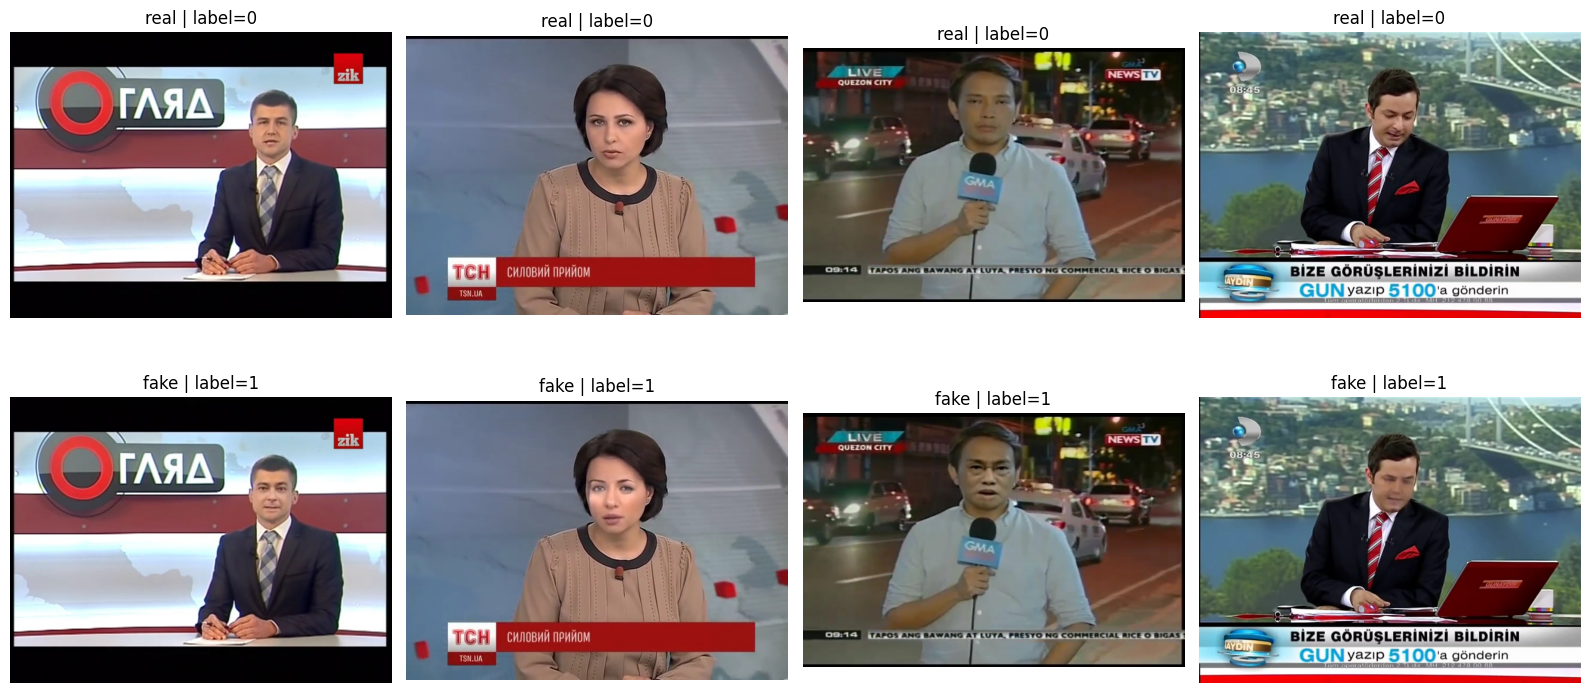

In [ ]:
import matplotlib.pyplot as plt

preview = pd.concat([
    train_df[train_df.label == 0].sample(min(4, (train_df.label == 0).sum()), random_state=SEED),
    train_df[train_df.label == 1].sample(min(4, (train_df.label == 1).sum()), random_state=SEED)
]).reset_index(drop=True)

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, row in zip(axes.flat, preview.itertuples(index=False)):
    with Image.open(row.image_path) as im:
        ax.imshow(im.convert("RGB"))
    ax.set_title(f"{row.class_name} | label={row.label}")
    ax.axis("off")
plt.tight_layout()
plt.show()

## 9. Define deterministic transforms and datasets

Training augmentation is intentionally moderate. Validation and test use only resize, tensor conversion, and ImageNet normalization.

In [ ]:
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

train_transform = transforms.Compose([
    transforms.Resize((FRAME_SIZE, FRAME_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ColorJitter(brightness=0.08, contrast=0.08, saturation=0.05, hue=0.02),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

eval_transform = transforms.Compose([
    transforms.Resize((FRAME_SIZE, FRAME_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

class FrameDataset(Dataset):
    def __init__(self, dataframe, transform):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):
        row = self.df.iloc[index]
        with Image.open(row.image_path) as im:
            image = im.convert("RGB")
        x = self.transform(image)
        y = int(row.label)
        return x, y

BATCH_SIZE = 32
NUM_WORKERS = 2 if DEVICE.type == "cuda" else 0

train_loader = DataLoader(
    FrameDataset(train_df, train_transform),
    batch_size=BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == "cuda")
)
val_loader = DataLoader(
    FrameDataset(val_df, eval_transform),
    batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == "cuda")
)
test_loader = DataLoader(
    FrameDataset(test_df, eval_transform),
    batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == "cuda")
)

xb, yb = next(iter(train_loader))
print("Batch image shape:", tuple(xb.shape))
print("Batch labels:", yb[:10].tolist())
assert xb.shape[1:] == (3, FRAME_SIZE, FRAME_SIZE)

Batch image shape: (32, 3, 224, 224)
Batch labels: [0, 1, 1, 0, 0, 1, 0, 1, 0, 0]


## 10. Create EfficientNet-B0

The classifier output indices are explicitly fixed:
- output index `0` = Real
- output index `1` = Fake

The model uses ImageNet-pretrained weights. If Colab cannot download the weights, the cell will stop with a clear error rather than silently switching to random initialization.

In [ ]:
from torchvision.models import EfficientNet_B0_Weights

weights = EfficientNet_B0_Weights.DEFAULT
model = models.efficientnet_b0(weights=weights)
in_features = model.classifier[1].in_features
model.classifier[1] = torch.nn.Linear(in_features, 2)
model = model.to(DEVICE)

CLASS_TO_LABEL = {"real": 0, "fake": 1}
LABEL_TO_CLASS = {0: "real", 1: "fake"}

print("Architecture: EfficientNet-B0")
print("Class mapping:", CLASS_TO_LABEL)
print("Output order: index 0 = Real; index 1 = Fake")

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 53.0MB/s]


Architecture: EfficientNet-B0
Class mapping: {'real': 0, 'fake': 1}
Output order: index 0 = Real; index 1 = Fake


## 11. Training and validation helpers

The primary validation criterion is **video-level ROC-AUC**, computed by averaging the frame-level fake probabilities for each validation video. The test set is not used for model selection.

If the validation AUC is undefined, the notebook stops rather than selecting a checkpoint using invalid metrics.

In [ ]:
def predict_dataframe(model, dataframe, transform, batch_size=32):
    loader = DataLoader(
        FrameDataset(dataframe, transform),
        batch_size=batch_size,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=(DEVICE.type == "cuda")
    )
    model.eval()
    probs, labels, paths = [], [], []
    offset = 0
    with torch.no_grad():
        for xb, yb in loader:
            xb = xb.to(DEVICE, non_blocking=True)
            logits = model(xb)
            fake_probs = torch.softmax(logits, dim=1)[:, 1]
            probs.extend(fake_probs.cpu().numpy().tolist())
            labels.extend(yb.numpy().tolist())
            batch_paths = dataframe.iloc[offset:offset + len(yb)]["video_path"].tolist()
            paths.extend(batch_paths)
            offset += len(yb)

    return pd.DataFrame({
        "video_path": paths,
        "label": labels,
        "fake_probability": probs
    })

def video_level_predictions(frame_predictions):
    return (
        frame_predictions.groupby("video_path", as_index=False)
        .agg(
            label=("label", "first"),
            fake_probability=("fake_probability", "mean"),
            frame_count=("fake_probability", "size")
        )
        .assign(prediction=lambda d: (d.fake_probability >= 0.5).astype(int))
    )

def calculate_metrics(predictions):
    y = predictions["label"].astype(int).to_numpy()
    p = predictions["fake_probability"].astype(float).to_numpy()
    pred = (p >= 0.5).astype(int)
    return {
        "videos": int(len(y)),
        "accuracy": float(accuracy_score(y, pred)),
        "precision_fake": float(precision_score(y, pred, zero_division=0)),
        "recall_fake": float(recall_score(y, pred, zero_division=0)),
        "f1_fake": float(f1_score(y, pred, zero_division=0)),
        "roc_auc": float(roc_auc_score(y, p)) if len(np.unique(y)) == 2 else None
    }

def evaluate_validation(model):
    fp = predict_dataframe(model, val_df, eval_transform)
    vp = video_level_predictions(fp)
    return calculate_metrics(vp), vp

## 12. Train with early stopping and save the best validation checkpoint

The model is trained with cross-entropy using the fixed label mapping. Training loss and validation video-level AUC are recorded each epoch. Early stopping limits unnecessary overfitting.

You can increase `MAX_EPOCHS` later, but do not tune based on the test results.

In [ ]:
MAX_EPOCHS = 12
PATIENCE = 4
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4

criterion = torch.nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(
    model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY
)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="max", factor=0.5, patience=2
)

BEST_PATH = OUTPUT_ROOT / "verisight_efficientnet_b0_ffpp_source_disjoint.pth"
history = []
best_val_auc = -float("inf")
epochs_without_improvement = 0

scaler = torch.amp.GradScaler("cuda", enabled=(DEVICE.type == "cuda"))

for epoch in range(1, MAX_EPOCHS + 1):
    model.train()
    running_loss, seen = 0.0, 0

    for xb, yb in train_loader:
        xb = xb.to(DEVICE, non_blocking=True)
        yb = yb.to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast("cuda", enabled=(DEVICE.type == "cuda")):
            logits = model(xb)
            loss = criterion(logits, yb)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item() * len(yb)
        seen += len(yb)

    train_loss = running_loss / max(seen, 1)
    val_metrics, val_video_predictions = evaluate_validation(model)
    val_auc = val_metrics["roc_auc"]

    if val_auc is None:
        raise RuntimeError("Validation ROC-AUC is undefined. Check validation labels.")

    scheduler.step(val_auc)
    current_lr = optimizer.param_groups[0]["lr"]

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_video_auc": val_auc,
        "val_video_accuracy_at_0_5": val_metrics["accuracy"],
        "learning_rate": current_lr
    })

    print(
        f"Epoch {epoch:02d}/{MAX_EPOCHS} | "
        f"train loss {train_loss:.4f} | "
        f"val video AUC {val_auc:.4f} | "
        f"val video accuracy {val_metrics['accuracy']:.4f} | "
        f"lr {current_lr:.2e}"
    )

    # Select checkpoint by validation video AUC only.
    if val_auc > best_val_auc:
        best_val_auc = val_auc
        epochs_without_improvement = 0

        torch.save({
            "architecture": "efficientnet_b0",
            "state_dict": model.state_dict(),
            "classes": ["real", "fake"],
            "class_to_label": CLASS_TO_LABEL,
            "label_to_class": LABEL_TO_CLASS,
            "input_size": FRAME_SIZE,
            "mean": IMAGENET_MEAN,
            "std": IMAGENET_STD,
            "best_validation_video_auc": best_val_auc,
            "seed": SEED
        }, BEST_PATH)
        print("  Saved best validation checkpoint.")
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:
        print("Early stopping: validation video AUC did not improve.")
        break

history_df = pd.DataFrame(history)
history_path = REPORT_ROOT / "verisight_training_history.csv"
history_df.to_csv(history_path, index=False)

print("\nBest validation video AUC:", round(best_val_auc, 4))
print("Checkpoint:", BEST_PATH)
print("Training history:", history_path)

Epoch 01/12 | train loss 0.7142 | val video AUC 0.6224 | val video accuracy 0.6429 | lr 1.00e-04
  Saved best validation checkpoint.
Epoch 02/12 | train loss 0.6514 | val video AUC 0.7296 | val video accuracy 0.7857 | lr 1.00e-04
  Saved best validation checkpoint.
Epoch 03/12 | train loss 0.5693 | val video AUC 0.8776 | val video accuracy 0.7500 | lr 1.00e-04
  Saved best validation checkpoint.
Epoch 04/12 | train loss 0.4379 | val video AUC 0.8878 | val video accuracy 0.7500 | lr 1.00e-04
  Saved best validation checkpoint.
Epoch 05/12 | train loss 0.3133 | val video AUC 0.9031 | val video accuracy 0.7500 | lr 1.00e-04
  Saved best validation checkpoint.
Epoch 06/12 | train loss 0.2350 | val video AUC 0.8827 | val video accuracy 0.7500 | lr 1.00e-04
Epoch 07/12 | train loss 0.1992 | val video AUC 0.9082 | val video accuracy 0.7500 | lr 1.00e-04
  Saved best validation checkpoint.
Epoch 08/12 | train loss 0.1701 | val video AUC 0.9082 | val video accuracy 0.7857 | lr 1.00e-04
Epoch 09

## 13. Load the best checkpoint and evaluate the test set once

The held-out test set is evaluated only after checkpoint selection. The primary metrics are calculated at video level, not by treating multiple frames from one video as independent test examples.

In [ ]:
checkpoint = torch.load(BEST_PATH, map_location=DEVICE, weights_only=False)

assert checkpoint["classes"] == ["real", "fake"]
assert checkpoint["class_to_label"] == {"real": 0, "fake": 1}

best_model = models.efficientnet_b0(weights=None)
best_in_features = best_model.classifier[1].in_features
best_model.classifier[1] = torch.nn.Linear(best_in_features, 2)
best_model.load_state_dict(checkpoint["state_dict"])
best_model = best_model.to(DEVICE)
best_model.eval()

test_frame_predictions = predict_dataframe(best_model, test_df, eval_transform)
test_video_predictions = video_level_predictions(test_frame_predictions)
test_metrics = calculate_metrics(test_video_predictions)

print("TEST VIDEO-LEVEL METRICS")
print(json.dumps(test_metrics, indent=2))
print("\nCONFUSION MATRIX (rows actual [real,fake], columns predicted [real,fake])")
print(confusion_matrix(
    test_video_predictions["label"],
    test_video_predictions["prediction"],
    labels=[0, 1]
))
print("\nCLASSIFICATION REPORT")
print(classification_report(
    test_video_predictions["label"],
    test_video_predictions["prediction"],
    labels=[0, 1],
    target_names=["Real", "Fake"],
    zero_division=0
))

test_video_path = REPORT_ROOT / "verisight_test_video_predictions.csv"
test_frame_path = REPORT_ROOT / "verisight_test_frame_predictions.csv"
metrics_path = REPORT_ROOT / "verisight_test_metrics.json"

test_video_predictions.to_csv(test_video_path, index=False)
test_frame_predictions.to_csv(test_frame_path, index=False)
metrics_path.write_text(json.dumps(test_metrics, indent=2))

print("\nSaved video predictions:", test_video_path)
print("Saved frame predictions:", test_frame_path)
print("Saved test metrics:", metrics_path)

TEST VIDEO-LEVEL METRICS
{
  "videos": 32,
  "accuracy": 0.6875,
  "precision_fake": 0.875,
  "recall_fake": 0.4375,
  "f1_fake": 0.5833333333333334,
  "roc_auc": 0.73828125
}

CONFUSION MATRIX (rows actual [real,fake], columns predicted [real,fake])
[[15  1]
 [ 9  7]]

CLASSIFICATION REPORT
              precision    recall  f1-score   support

        Real       0.62      0.94      0.75        16
        Fake       0.88      0.44      0.58        16

    accuracy                           0.69        32
   macro avg       0.75      0.69      0.67        32
weighted avg       0.75      0.69      0.67        32


Saved video predictions: /content/drive/MyDrive/VeriSight_AI_Storage/reports/verisight_test_video_predictions.csv
Saved frame predictions: /content/drive/MyDrive/VeriSight_AI_Storage/reports/verisight_test_frame_predictions.csv
Saved test metrics: /content/drive/MyDrive/VeriSight_AI_Storage/reports/verisight_test_metrics.json


## 14. Sanity checks and probability direction

This reports mean predicted fake probability for each true class. A useful model should generally assign higher fake probabilities to the fake class. Do not reverse probabilities to make metrics look better.

A low or reversed AUC means the baseline has failed and needs further investigation; it is not a reason to change the established labels.

In [ ]:
print("Mean predicted fake probability by actual class:")
display(
    test_video_predictions.groupby("label")["fake_probability"]
    .agg(["count", "mean", "min", "max"])
    .rename(index={0: "REAL", 1: "FAKE"})
)

print("Class mapping in checkpoint:", checkpoint["class_to_label"])
print("Validation AUC used for checkpoint selection:", checkpoint["best_validation_video_auc"])
print("Test AUC:", test_metrics["roc_auc"])

assert set(test_video_predictions["label"].unique()) == {0, 1}
assert test_video_predictions["video_path"].is_unique

Mean predicted fake probability by actual class:


,count,mean,min,max
label,,,,
REAL,16,0.207122,0.000124,0.702911
FAKE,16,0.484462,0.004875,0.996528


Class mapping in checkpoint: {'real': 0, 'fake': 1}
Validation AUC used for checkpoint selection: 0.9183673469387755
Test AUC: 0.73828125


## 15. Export a compact inference package for the FastAPI stage

This creates a folder containing the selected model checkpoint and preprocessing metadata. The FastAPI application still needs an inference adapter that loads this checkpoint, extracts frames from uploads, applies the same resize/normalization, and aggregates frame scores.

**This notebook does not automatically modify or integrate the FastAPI application.**

In [ ]:
INFERENCE_DIR = STORAGE / "verisight_inference_package"
INFERENCE_DIR.mkdir(parents=True, exist_ok=True)

shutil.copy2(BEST_PATH, INFERENCE_DIR / "verisight_efficientnet_b0_ffpp.pth")

inference_config = {
    "architecture": "efficientnet_b0",
    "input_size": FRAME_SIZE,
    "color_mode": "RGB",
    "mean": list(IMAGENET_MEAN),
    "std": list(IMAGENET_STD),
    "class_to_label": {"real": 0, "fake": 1},
    "output_index_0": "real",
    "output_index_1": "fake",
    "video_aggregation": "mean of sampled frame fake probabilities",
    "training_dataset": "FaceForensics++ C23 200 subset",
    "split_method": "source-identity connected-component disjoint"
}
(INFERENCE_DIR / "inference_config.json").write_text(json.dumps(inference_config, indent=2))

print("Inference package:", INFERENCE_DIR)
print("Files:", [p.name for p in INFERENCE_DIR.iterdir()])

Inference package: /content/drive/MyDrive/VeriSight_AI_Storage/verisight_inference_package
Files: ['verisight_efficientnet_b0_ffpp.pth', 'inference_config.json']


## 16. Final experiment summary

Use these results in project documentation only if the run completed and the test metrics are valid. Do not describe this as a complete multimodal detector: this notebook trains only the EfficientNet-B0 frame branch.

In [ ]:
summary = {
    "dataset_root": str(DATASET_ROOT),
    "real_videos_found": int(len(real_paths)),
    "fake_videos_found": int(len(fake_paths)),
    "videos_in_split": {
        split: int((split_table.split == split).sum())
        for split in ["train", "validation", "test"]
    },
    "frames_in_split": {
        "train": int(len(train_df)),
        "validation": int(len(val_df)),
        "test": int(len(test_df))
    },
    "source_overlap": {
        "train_validation": int(len(source_sets["train"] & source_sets["validation"])),
        "train_test": int(len(source_sets["train"] & source_sets["test"])),
        "validation_test": int(len(source_sets["validation"] & source_sets["test"]))
    },
    "best_validation_video_auc": float(best_val_auc),
    "test_video_metrics": test_metrics,
    "checkpoint": str(BEST_PATH)
}

summary_path = REPORT_ROOT / "verisight_experiment_summary.json"
summary_path.write_text(json.dumps(summary, indent=2))
print(json.dumps(summary, indent=2))
print("\nExperiment summary saved:", summary_path)

{
  "dataset_root": "/content/drive/MyDrive/VeriSight_AI_Storage/datasets/video/FaceForensics++_c23_200",
  "real_videos_found": 100,
  "fake_videos_found": 100,
  "videos_in_split": {
    "train": 140,
    "validation": 28,
    "test": 32
  },
  "frames_in_split": {
    "train": 1120,
    "validation": 224,
    "test": 256
  },
  "source_overlap": {
    "train_validation": 0,
    "train_test": 0,
    "validation_test": 0
  },
  "best_validation_video_auc": 0.9183673469387755,
  "test_video_metrics": {
    "videos": 32,
    "accuracy": 0.6875,
    "precision_fake": 0.875,
    "recall_fake": 0.4375,
    "f1_fake": 0.5833333333333334,
    "roc_auc": 0.73828125
  },
  "checkpoint": "/content/drive/MyDrive/VeriSight_AI_Storage/models/verisight_efficientnet_b0_ffpp_source_disjoint.pth"
}

Experiment summary saved: /content/drive/MyDrive/VeriSight_AI_Storage/reports/verisight_experiment_summary.json


## Troubleshooting and interpretation

- **Drive mount error:** if `/content/drive/MyDrive` already exists, do not mount again. Restart runtime only if the mount is genuinely broken.
- **Dataset not found:** verify the exact folder structure in `VeriSight_AI_Storage/datasets/video/FaceForensics++_c23_200`.
- **CUDA out of memory:** reduce `BATCH_SIZE` from 32 to 16 or 8, then rerun from the dataset-loader cell if necessary.
- **Source split assertion fails:** the current subset may not contain enough independent connected source groups for a three-way split. Do not remove the assertion or fall back to random frame splitting.
- **Poor test metrics:** report them honestly. Inspect training curves, dataset provenance, split counts, and cross-dataset performance before changing labels or reversing probabilities.
- **No test fake videos:** do not calculate a fake-detection score from a one-class test set.

### What remains for VeriSight AI
1. Integrate this checkpoint into FastAPI with matching preprocessing.
2. Test actual video uploads through the React frontend.
3. Add a temporal video model.
4. Build the audio branch using valid genuine/fake audio training data (for example, ASVspoof protocols and WaveFake with genuine samples).
5. Implement late fusion and explainability.
6. Evaluate on independent datasets such as Celeb-DF and DFDC. Keep Deepfake-Eval-2024 evaluation-only under its dataset terms.

In [ ]:

from pathlib import Path
from collections import Counter
import cv2

BASE = Path(
    "/content/drive/MyDrive/VeriSight_AI_Storage/datasets/video"
)

folders = [
    BASE / "FaceForensics++_c23_200",
    BASE / "FaceForensics++_test"
]

for folder in folders:
    print(f"\n{'=' * 60}")
    print("DATASET:", folder.name)
    print("EXISTS:", folder.exists())

    if not folder.exists():
        continue

    videos = [
        p for p in folder.rglob("*")
        if p.suffix.lower() in {".mp4", ".avi", ".mov"}
    ]

    print("Total video files:", len(videos))

    parent_counts = Counter(
        video.parent.name for video in videos
    )

    print("\nVideos by parent folder:")
    for name, count in sorted(parent_counts.items()):
        print(f"{name}: {count}")

    print("\nSample videos:")
    for video in videos[:5]:
        print(video.relative_to(folder))

    print("\nVideo metadata:")
    for video in videos[:3]:
        cap = cv2.VideoCapture(str(video))

        if cap.isOpened():
            frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
            fps = cap.get(cv2.CAP_PROP_FPS)
            width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
            height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

            duration = frames / fps if fps > 0 else 0

            print({
                "file": video.name,
                "frames": frames,
                "fps": round(fps, 2),
                "resolution": f"{width}x{height}",
                "duration_seconds": round(duration, 2)
            })

        cap.release()



DATASET: FaceForensics++_c23_200
EXISTS: False

DATASET: FaceForensics++_test
EXISTS: False


In [ ]:

from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:

from pathlib import Path

root = Path("/content/drive/MyDrive")

print("Google Drive mounted:", root.exists())
print("\nFolders in MyDrive:\n")

for item in sorted(root.iterdir()):
    if item.is_dir():
        print(item.name)


Google Drive mounted: True

Folders in MyDrive:

Bharat Space 🚀
Classroom
Colab Notebooks
VeriSight_AI_Storage


In [ ]:

from pathlib import Path

storage = Path(
    "/content/drive/MyDrive/VeriSight_AI_Storage"
)

print("Storage exists:", storage.exists())
print("\nTop-level contents:\n")

for item in sorted(storage.iterdir()):
    kind = "DIR " if item.is_dir() else "FILE"
    print(f"{kind}  {item.name}")


Storage exists: True

Top-level contents:

DIR   cache
DIR   datasets
DIR   evaluation
DIR   logs
DIR   manifests
DIR   models
DIR   processed
DIR   reports
DIR   results
DIR   verisight_ffpp_baseline
DIR   verisight_inference_package


In [ ]:

from pathlib import Path

datasets = Path(
    "/content/drive/MyDrive/VeriSight_AI_Storage/datasets"
)

print("DATASETS DIRECTORY:", datasets)
print("\nFolder structure:\n")

for item in sorted(datasets.iterdir()):
    if item.is_dir():
        print(f"\n📁 {item.name}")

        for child in sorted(item.iterdir())[:20]:
            kind = "📁" if child.is_dir() else "📄"
            print(f"   {kind} {child.name}")
    else:
        print(f"📄 {item.name}")


DATASETS DIRECTORY: /content/drive/MyDrive/VeriSight_AI_Storage/datasets

Folder structure:


📁 audio

📁 evaluation

📁 image

📁 video
   📁 FaceForensics++_c23_200
   📁 FaceForensics++_test


In [ ]:

from pathlib import Path
from collections import Counter

video_root = Path(
    "/content/drive/MyDrive/VeriSight_AI_Storage/datasets/video"
)

for folder_name in [
    "FaceForensics++_c23_200",
    "FaceForensics++_test"
]:
    folder = video_root / folder_name

    print("\n" + "=" * 60)
    print("DATASET:", folder_name)
    print("EXISTS:", folder.exists())

    if not folder.exists():
        continue

    files = [
        p for p in folder.rglob("*")
        if p.is_file()
    ]

    extensions = Counter(p.suffix.lower() for p in files)

    print("Total files:", len(files))
    print("File extensions:", dict(extensions))

    print("\nTop-level folders:")
    for item in sorted(folder.iterdir()):
        if item.is_dir():
            print("  ", item.name)

    videos = [
        p for p in files
        if p.suffix.lower() in {".mp4", ".avi", ".mov"}
    ]

    print("\nVideo count:", len(videos))
    print("Sample video paths:")

    for video in videos[:10]:
        print("  ", video.relative_to(folder))



DATASET: FaceForensics++_c23_200
EXISTS: True
Total files: 200
File extensions: {'.mp4': 200}

Top-level folders:
   manipulated_sequences
   original_sequences

Video count: 200
Sample video paths:
   manipulated_sequences/Deepfakes/c23/videos/585_599.mp4
   manipulated_sequences/Deepfakes/c23/videos/599_585.mp4
   manipulated_sequences/Deepfakes/c23/videos/469_481.mp4
   manipulated_sequences/Deepfakes/c23/videos/481_469.mp4
   manipulated_sequences/Deepfakes/c23/videos/183_253.mp4
   manipulated_sequences/Deepfakes/c23/videos/253_183.mp4
   manipulated_sequences/Deepfakes/c23/videos/672_720.mp4
   manipulated_sequences/Deepfakes/c23/videos/720_672.mp4
   manipulated_sequences/Deepfakes/c23/videos/866_878.mp4
   manipulated_sequences/Deepfakes/c23/videos/878_866.mp4

DATASET: FaceForensics++_test
EXISTS: True
Total files: 20
File extensions: {'.mp4': 20}

Top-level folders:
   manipulated_sequences
   original_sequences

Video count: 20
Sample video paths:
   manipulated_sequences/D

In [ ]:

from pathlib import Path
from collections import Counter

root = Path(
    "/content/drive/MyDrive/VeriSight_AI_Storage/datasets/video"
)

train_dir = root / "FaceForensics++_c23_200"
test_dir = root / "FaceForensics++_test"

def collect_videos(folder):
    return {
        str(p.relative_to(folder)): p
        for p in folder.rglob("*.mp4")
    }

train = collect_videos(train_dir)
test = collect_videos(test_dir)

def count_classes(videos):
    counts = Counter()

    for relative_path in videos:
        if relative_path.startswith("original_sequences/"):
            counts["real"] += 1
        elif relative_path.startswith("manipulated_sequences/"):
            counts["fake"] += 1
        else:
            counts["unknown"] += 1

    return counts

print("TRAIN CLASS COUNTS:", count_classes(train))
print("TEST CLASS COUNTS:", count_classes(test))

overlap = set(train) & set(test)

print("\nEXACT RELATIVE PATH OVERLAP:", len(overlap))

for path in sorted(overlap)[:20]:
    print(path)

print("\nTRAIN SAMPLE PATHS:")
for path in sorted(train)[:8]:
    print(path)

print("\nTEST SAMPLE PATHS:")
for path in sorted(test)[:8]:
    print(path)


TRAIN CLASS COUNTS: Counter({'fake': 100, 'real': 100})
TEST CLASS COUNTS: Counter({'fake': 10, 'real': 10})

EXACT RELATIVE PATH OVERLAP: 20
manipulated_sequences/Deepfakes/c23/videos/183_253.mp4
manipulated_sequences/Deepfakes/c23/videos/253_183.mp4
manipulated_sequences/Deepfakes/c23/videos/469_481.mp4
manipulated_sequences/Deepfakes/c23/videos/481_469.mp4
manipulated_sequences/Deepfakes/c23/videos/585_599.mp4
manipulated_sequences/Deepfakes/c23/videos/599_585.mp4
manipulated_sequences/Deepfakes/c23/videos/672_720.mp4
manipulated_sequences/Deepfakes/c23/videos/720_672.mp4
manipulated_sequences/Deepfakes/c23/videos/866_878.mp4
manipulated_sequences/Deepfakes/c23/videos/878_866.mp4
original_sequences/youtube/c23/videos/183.mp4
original_sequences/youtube/c23/videos/253.mp4
original_sequences/youtube/c23/videos/469.mp4
original_sequences/youtube/c23/videos/481.mp4
original_sequences/youtube/c23/videos/585.mp4
original_sequences/youtube/c23/videos/599.mp4
original_sequences/youtube/c23/v

In [ ]:

from pathlib import Path
from collections import defaultdict

root = Path(
    "/content/drive/MyDrive/VeriSight_AI_Storage/datasets/video/FaceForensics++_c23_200"
)

original_dir = root / "original_sequences/youtube/c23/videos"
fake_dir = root / "manipulated_sequences/Deepfakes/c23/videos"

original_ids = {
    p.stem for p in original_dir.glob("*.mp4")
}

fake_pairs = []
source_usage = defaultdict(list)

for p in fake_dir.glob("*.mp4"):
    parts = p.stem.split("_")

    if len(parts) != 2:
        continue

    source_a, source_b = parts
    fake_pairs.append((p.name, source_a, source_b))

    source_usage[source_a].append(p.name)
    source_usage[source_b].append(p.name)

print("Original source videos:", len(original_ids))
print("Manipulated videos:", len(fake_pairs))
print("Unique source IDs in manipulated videos:", len(source_usage))

print("\nMissing original source IDs:")
missing = sorted(set(source_usage) - original_ids)
print(missing)

print("\nMost frequently reused source IDs:")
for source_id, clips in sorted(
    source_usage.items(),
    key=lambda x: len(x[1]),
    reverse=True
)[:15]:
    print(source_id, "->", len(clips), "manipulated clips")

print("\nSample manipulated source pairs:")
for item in fake_pairs[:10]:
    print(item)


Original source videos: 100
Manipulated videos: 100
Unique source IDs in manipulated videos: 100

Missing original source IDs:
[]

Most frequently reused source IDs:
585 -> 2 manipulated clips
599 -> 2 manipulated clips
469 -> 2 manipulated clips
481 -> 2 manipulated clips
183 -> 2 manipulated clips
253 -> 2 manipulated clips
672 -> 2 manipulated clips
720 -> 2 manipulated clips
866 -> 2 manipulated clips
878 -> 2 manipulated clips
339 -> 2 manipulated clips
392 -> 2 manipulated clips
828 -> 2 manipulated clips
830 -> 2 manipulated clips
252 -> 2 manipulated clips

Sample manipulated source pairs:
('585_599.mp4', '585', '599')
('599_585.mp4', '599', '585')
('469_481.mp4', '469', '481')
('481_469.mp4', '481', '469')
('183_253.mp4', '183', '253')
('253_183.mp4', '253', '183')
('672_720.mp4', '672', '720')
('720_672.mp4', '720', '672')
('866_878.mp4', '866', '878')
('878_866.mp4', '878', '866')


In [ ]:

from pathlib import Path
from collections import defaultdict, Counter

root = Path(
    "/content/drive/MyDrive/VeriSight_AI_Storage/datasets/video/FaceForensics++_c23_200"
)

fake_dir = root / "manipulated_sequences/Deepfakes/c23/videos"

pair_groups = defaultdict(list)
source_to_pairs = defaultdict(set)

for video in fake_dir.glob("*.mp4"):
    parts = video.stem.split("_")

    if len(parts) != 2:
        continue

    a, b = parts
    pair_key = tuple(sorted((a, b)))

    pair_groups[pair_key].append(video.name)
    source_to_pairs[a].add(pair_key)
    source_to_pairs[b].add(pair_key)

print("Unique source-pair groups:", len(pair_groups))
print("Manipulated videos:", sum(map(len, pair_groups.values())))

print("\nPair group size distribution:")
print(Counter(len(v) for v in pair_groups.values()))

print("\nSource IDs used in multiple different pairs:")
reused = {
    source: pairs
    for source, pairs in source_to_pairs.items()
    if len(pairs) > 1
}
print("Count:", len(reused))

for source, pairs in list(sorted(reused.items()))[:15]:
    print(source, "->", sorted(pairs))

print("\nSample pair groups:")
for pair, videos in list(sorted(pair_groups.items()))[:10]:
    print(pair, "->", sorted(videos))


Unique source-pair groups: 50
Manipulated videos: 100

Pair group size distribution:
Counter({2: 50})

Source IDs used in multiple different pairs:
Count: 0

Sample pair groups:
('033', '097') -> ['033_097.mp4', '097_033.mp4']
('035', '036') -> ['035_036.mp4', '036_035.mp4']
('044', '945') -> ['044_945.mp4', '945_044.mp4']
('046', '904') -> ['046_904.mp4', '904_046.mp4']
('055', '147') -> ['055_147.mp4', '147_055.mp4']
('062', '066') -> ['062_066.mp4', '066_062.mp4']
('107', '109') -> ['107_109.mp4', '109_107.mp4']
('128', '896') -> ['128_896.mp4', '896_128.mp4']
('134', '192') -> ['134_192.mp4', '192_134.mp4']
('150', '153') -> ['150_153.mp4', '153_150.mp4']


In [ ]:


from pathlib import Path
import random
import csv

storage = Path(
    "/content/drive/MyDrive/VeriSight_AI_Storage"
)

root = storage / "datasets/video/FaceForensics++_c23_200"
original_dir = root / "original_sequences/youtube/c23/videos"
fake_dir = root / "manipulated_sequences/Deepfakes/c23/videos"

manifest_dir = storage / "manifests"
manifest_dir.mkdir(parents=True, exist_ok=True)

# Build source-pair groups
groups = {}

for fake_video in fake_dir.glob("*.mp4"):
    a, b = fake_video.stem.split("_")
    pair = tuple(sorted((a, b)))
    groups.setdefault(pair, []).append(fake_video)

# Deterministic group-level split
pairs = sorted(groups.keys())
random.Random(42).shuffle(pairs)

train_pairs = pairs[:35]
val_pairs = pairs[35:42]
test_pairs = pairs[42:50]

split_assignments = {
    "train": train_pairs,
    "validation": val_pairs,
    "test": test_pairs
}

rows = []

for split, split_pairs in split_assignments.items():
    for a, b in split_pairs:

        # Original videos
        for source_id in (a, b):
            path = original_dir / f"{source_id}.mp4"

            if not path.exists():
                raise FileNotFoundError(path)

            rows.append({
                "split": split,
                "video_path": str(path),
                "label": "real",
                "source_a": a,
                "source_b": b,
                "group_id": f"{a}_{b}"
            })

        # Both manipulation directions
        for fake_path in groups[(a, b)]:
            rows.append({
                "split": split,
                "video_path": str(fake_path),
                "label": "fake",
                "source_a": a,
                "source_b": b,
                "group_id": f"{a}_{b}"
            })

# Save CSV manifest
output = manifest_dir / "temporal_source_disjoint_split_seed42.csv"

with output.open("w", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=rows[0].keys())
    writer.writeheader()
    writer.writerows(rows)

# Verify split counts and source disjointness
for split in ("train", "validation", "test"):
    selected = [r for r in rows if r["split"] == split]
    real_count = sum(r["label"] == "real" for r in selected)
    fake_count = sum(r["label"] == "fake" for r in selected)

    print(
        f"{split:10} | Total: {len(selected):3} "
        f"| Real: {real_count:3} | Fake: {fake_count:3}"
    )

source_sets = {
    split: {
        source
        for pair in split_pairs
        for source in pair
    }
    for split, split_pairs in split_assignments.items()
}

assert source_sets["train"].isdisjoint(source_sets["validation"])
assert source_sets["train"].isdisjoint(source_sets["test"])
assert source_sets["validation"].isdisjoint(source_sets["test"])

assert len(rows) == 200

print("\nSource-disjoint verification: PASSED")
print("Manifest saved:", output)
print("Total records:", len(rows))



train      | Total: 140 | Real:  70 | Fake:  70
validation | Total:  28 | Real:  14 | Fake:  14
test       | Total:  32 | Real:  16 | Fake:  16

Source-disjoint verification: PASSED
Manifest saved: /content/drive/MyDrive/VeriSight_AI_Storage/manifests/temporal_source_disjoint_split_seed42.csv
Total records: 200


In [ ]:

import pandas as pd
import cv2
from pathlib import Path

manifest = pd.read_csv(
    "/content/drive/MyDrive/VeriSight_AI_Storage/manifests/temporal_source_disjoint_split_seed42.csv"
)

print("Checking video metadata...")

records = []

for _, row in manifest.iterrows():
    path = Path(row["video_path"])
    cap = cv2.VideoCapture(str(path))

    if not cap.isOpened():
        records.append({
            "file": path.name,
            "split": row["split"],
            "label": row["label"],
            "readable": False
        })
        continue

    frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    fps = cap.get(cv2.CAP_PROP_FPS)
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

    cap.release()

    records.append({
        "file": path.name,
        "split": row["split"],
        "label": row["label"],
        "readable": True,
        "frames": frames,
        "fps": fps,
        "width": width,
        "height": height,
        "duration": frames / fps if fps > 0 else 0
    })

df = pd.DataFrame(records)

print("\nReadable videos:", df["readable"].sum())
print("Unreadable videos:", (~df["readable"]).sum())

valid = df[df["readable"]]

print("\nFrame count statistics:")
print(valid["frames"].describe())

print("\nDuration statistics (seconds):")
print(valid["duration"].describe())

print("\nResolution distribution:")
print(valid.groupby(["width", "height"]).size())

print("\nVideos shorter than 16 frames:",
      (valid["frames"] < 16).sum())

print("\nUnreadable video examples:")
print(df[~df["readable"]].head(10))


Checking video metadata...

Readable videos: 200
Unreadable videos: 0

Frame count statistics:
count     200.000000
mean      516.780000
std       216.368919
min       287.000000
25%       359.000000
50%       463.500000
75%       568.250000
max      1496.000000
Name: frames, dtype: float64

Duration statistics (seconds):
count    200.000000
mean      19.286667
std        8.249595
min        9.566667
25%       13.306667
50%       17.053333
75%       22.350000
max       49.920000
Name: duration, dtype: float64

Resolution distribution:
width  height
600    480       18
602    480        2
640    480       50
654    480        2
656    480       20
720    480        4
800    480        2
854    480       14
1280   720       72
1920   1080      16
dtype: int64

Videos shorter than 16 frames: 0

Unreadable video examples:
Empty DataFrame
Columns: [file, split, label, readable, frames, fps, width, height, duration]
Index: []


In [ ]:
import cv2
import numpy as np
import pandas as pd
from pathlib import Path
from tqdm.auto import tqdm

storage = Path("/content/drive/MyDrive/VeriSight_AI_Storage")

manifest_path = storage / "manifests/temporal_source_disjoint_split_seed42.csv"
output_dir = storage / "processed/temporal_sequences"

output_dir.mkdir(parents=True, exist_ok=True)

manifest = pd.read_csv(manifest_path)

SEQUENCE_LENGTH = 16
IMAGE_SIZE = 224

records = []
failed = []

for _, row in tqdm(manifest.iterrows(), total=len(manifest)):

    video_path = Path(row["video_path"])
    cap = cv2.VideoCapture(str(video_path))

    if not cap.isOpened():
        failed.append(video_path.name)
        continue

    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    # Select 16 consecutive frames from the middle.
    start = max(0, (total_frames - SEQUENCE_LENGTH) // 2)

    cap.set(cv2.CAP_PROP_POS_FRAMES, start)

    frames = []

    for _ in range(SEQUENCE_LENGTH):
        success, frame = cap.read()

        if not success:
            break

        frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        frame = cv2.resize(
            frame,
            (IMAGE_SIZE, IMAGE_SIZE),
            interpolation=cv2.INTER_AREA
        )

        frames.append(frame)

    cap.release()

    if len(frames) != SEQUENCE_LENGTH:
        failed.append(video_path.name)
        continue

    sequence = np.stack(frames).astype(np.uint8)

    output_name = video_path.stem + ".npy"
    output_path = output_dir / output_name

    np.save(output_path, sequence)

    records.append({
        "video_name": video_path.name,
        "sequence_path": str(output_path),
        "split": row["split"],
        "label": row["label"],
        "group_id": row["group_id"],
        "frames": SEQUENCE_LENGTH,
        "height": IMAGE_SIZE,
        "width": IMAGE_SIZE
    })

sequence_manifest = pd.DataFrame(records)

sequence_manifest_path = (
    storage / "manifests/temporal_sequence_manifest_seed42.csv"
)

sequence_manifest.to_csv(sequence_manifest_path, index=False)

print("\nExtraction completed")
print("Successful sequences:", len(records))
print("Failed videos:", len(failed))
print("\nSequences by split:")
print(sequence_manifest.groupby(["split", "label"]).size())

print("\nExample sequence shape:")
if records:
    example = np.load(records[0]["sequence_path"])
    print(example.shape, example.dtype)

print("\nManifest saved:", sequence_manifest_path)
print("Sequence directory:", output_dir)

if failed:
    print("\nFailed video files:")
    print(failed)

  0%|          | 0/200 [00:00<?, ?it/s]


Extraction completed
Successful sequences: 200
Failed videos: 0

Sequences by split:
split       label
test        fake     16
            real     16
train       fake     70
            real     70
validation  fake     14
            real     14
dtype: int64

Example sequence shape:
(16, 224, 224, 3) uint8

Manifest saved: /content/drive/MyDrive/VeriSight_AI_Storage/manifests/temporal_sequence_manifest_seed42.csv
Sequence directory: /content/drive/MyDrive/VeriSight_AI_Storage/processed/temporal_sequences


In [ ]:
import torch
from pathlib import Path

checkpoint_path = Path(
    "/content/drive/MyDrive/VeriSight_AI_Storage/models/"
    "verisight_efficientnet_b0_ffpp_source_disjoint.pth"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=False
)

print("Checkpoint type:", type(checkpoint))

if isinstance(checkpoint, dict):
    print("\nCheckpoint keys:")
    for key in checkpoint.keys():
        print("-", key)

    state_dict = checkpoint.get(
        "model_state_dict",
        checkpoint.get("state_dict", checkpoint)
    )

    print("\nFirst 20 model parameter names:")
    for key in list(state_dict.keys())[:20]:
        print(key, tuple(state_dict[key].shape))

    print("\nClassifier-related parameters:")
    for key, value in state_dict.items():
        if "classifier" in key:
            print(key, tuple(value.shape))

Checkpoint type: <class 'dict'>

Checkpoint keys:
- architecture
- state_dict
- classes
- class_to_label
- label_to_class
- input_size
- mean
- std
- best_validation_video_auc
- seed

First 20 model parameter names:
features.0.0.weight (32, 3, 3, 3)
features.0.1.weight (32,)
features.0.1.bias (32,)
features.0.1.running_mean (32,)
features.0.1.running_var (32,)
features.0.1.num_batches_tracked ()
features.1.0.block.0.0.weight (32, 1, 3, 3)
features.1.0.block.0.1.weight (32,)
features.1.0.block.0.1.bias (32,)
features.1.0.block.0.1.running_mean (32,)
features.1.0.block.0.1.running_var (32,)
features.1.0.block.0.1.num_batches_tracked ()
features.1.0.block.1.fc1.weight (8, 32, 1, 1)
features.1.0.block.1.fc1.bias (8,)
features.1.0.block.1.fc2.weight (32, 8, 1, 1)
features.1.0.block.1.fc2.bias (32,)
features.1.0.block.2.0.weight (16, 32, 1, 1)
features.1.0.block.2.1.weight (16,)
features.1.0.block.2.1.bias (16,)
features.1.0.block.2.1.running_mean (16,)

Classifier-related parameters:
classi

In [ ]:
import torch
import torch.nn as nn
import torchvision.models as models
import numpy as np
import pandas as pd
from pathlib import Path
from tqdm.auto import tqdm

storage = Path("/content/drive/MyDrive/VeriSight_AI_Storage")

checkpoint_path = storage / "models/verisight_efficientnet_b0_ffpp_source_disjoint.pth"
manifest_path = storage / "manifests/temporal_sequence_manifest_seed42.csv"

sequence_dir = storage / "processed/temporal_sequences"
feature_dir = storage / "processed/temporal_features"
feature_dir.mkdir(parents=True, exist_ok=True)

# Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# Load checkpoint
checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=False
)

# Recreate the exact architecture
model = models.efficientnet_b0(weights=None)

# Match the checkpoint's 2-class classifier
model.classifier[1] = nn.Linear(1280, 2)

# Load trained weights
model.load_state_dict(checkpoint["state_dict"], strict=True)

# Keep only the feature extraction components
feature_extractor = nn.Sequential(
    model.features,
    model.avgpool,
    nn.Flatten(1)
)

feature_extractor = feature_extractor.to(device)
feature_extractor.eval()

# Freeze all parameters
for parameter in feature_extractor.parameters():
    parameter.requires_grad = False

print("EfficientNet-B0 loaded successfully.")
print("Feature dimension: 1280")

# Normalization from checkpoint
mean = torch.tensor(checkpoint["mean"], device=device).view(1, 3, 1, 1)
std = torch.tensor(checkpoint["std"], device=device).view(1, 3, 1, 1)

manifest = pd.read_csv(manifest_path)

records = []
failed = []

BATCH_SIZE = 32

for _, row in tqdm(manifest.iterrows(), total=len(manifest)):

    video_name = row["video_name"]
    sequence_path = sequence_dir / (Path(video_name).stem + ".npy")

    try:
        frames = np.load(sequence_path)

        if frames.shape != (16, 224, 224, 3):
            raise ValueError(f"Unexpected shape: {frames.shape}")

        frame_features = []

        with torch.inference_mode():

            for start in range(0, 16, BATCH_SIZE):
                batch = frames[start:start + BATCH_SIZE]

                x = torch.from_numpy(batch).to(device)
                x = x.permute(0, 3, 1, 2).float() / 255.0

                x = (x - mean) / std

                features = feature_extractor(x)
                frame_features.append(features.cpu().numpy())

        features = np.concatenate(frame_features, axis=0)

        if features.shape != (16, 1280):
            raise ValueError(f"Unexpected feature shape: {features.shape}")

        output_path = feature_dir / (Path(video_name).stem + ".npy")
        np.save(output_path, features.astype(np.float32))

        records.append({
            "video_name": video_name,
            "feature_path": str(output_path),
            "split": row["split"],
            "label": row["label"],
            "group_id": row["group_id"]
        })

    except Exception as e:
        failed.append((video_name, str(e)))

feature_manifest = pd.DataFrame(records)

feature_manifest_path = (
    storage / "manifests/temporal_feature_manifest_seed42.csv"
)

feature_manifest.to_csv(feature_manifest_path, index=False)

print("\nFeature extraction completed.")
print("Successful videos:", len(records))
print("Failed videos:", len(failed))

if records:
    example = np.load(records[0]["feature_path"])
    print("Example feature shape:", example.shape)
    print("Feature dtype:", example.dtype)

print("\nSplit distribution:")
print(feature_manifest.groupby(["split", "label"]).size())

print("\nFeature manifest:", feature_manifest_path)
print("Feature directory:", feature_dir)

if failed:
    print("\nFailures:")
    for item in failed[:10]:
        print(item)

Device: cuda
EfficientNet-B0 loaded successfully.
Feature dimension: 1280


  0%|          | 0/200 [00:00<?, ?it/s]


Feature extraction completed.
Successful videos: 200
Failed videos: 0
Example feature shape: (16, 1280)
Feature dtype: float32

Split distribution:
split       label
test        fake     16
            real     16
train       fake     70
            real     70
validation  fake     14
            real     14
dtype: int64

Feature manifest: /content/drive/MyDrive/VeriSight_AI_Storage/manifests/temporal_feature_manifest_seed42.csv
Feature directory: /content/drive/MyDrive/VeriSight_AI_Storage/processed/temporal_features


In [ ]:
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from pathlib import Path
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# --------------------------------------------------
# 1. Reproducibility
# --------------------------------------------------

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Training device:", device)

storage = Path("/content/drive/MyDrive/VeriSight_AI_Storage")

manifest_path = (
    storage / "manifests/temporal_feature_manifest_seed42.csv"
)

model_dir = storage / "models/temporal"
model_dir.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(manifest_path)

# --------------------------------------------------
# 2. Load feature sequences
# --------------------------------------------------

def load_split(split_name):

    subset = df[df["split"] == split_name]

    X, y = [], []

    for _, row in subset.iterrows():

        features = np.load(row["feature_path"])

        if features.shape != (16, 1280):
            raise ValueError(
                f"Invalid feature shape: {row['video_name']}"
            )

        X.append(features)

        # real = 0, fake = 1
        y.append(1 if row["label"] == "fake" else 0)

    return np.stack(X), np.array(y, dtype=np.float32)


X_train, y_train = load_split("train")
X_val, y_val = load_split("validation")
X_test, y_test = load_split("test")

print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)

# --------------------------------------------------
# 3. Normalize using TRAINING data only
# --------------------------------------------------

feature_mean = X_train.reshape(-1, 1280).mean(axis=0)
feature_std = X_train.reshape(-1, 1280).std(axis=0)

feature_std = np.maximum(feature_std, 1e-6)

def normalize_features(X):
    return ((X - feature_mean) / feature_std).astype(np.float32)

X_train = normalize_features(X_train)
X_val = normalize_features(X_val)
X_test = normalize_features(X_test)

# --------------------------------------------------
# 4. Create DataLoaders
# --------------------------------------------------

def make_loader(X, y, shuffle=False):

    dataset = TensorDataset(
        torch.tensor(X, dtype=torch.float32),
        torch.tensor(y, dtype=torch.float32)
    )

    return DataLoader(
        dataset,
        batch_size=16,
        shuffle=shuffle
    )

train_loader = make_loader(X_train, y_train, True)
val_loader = make_loader(X_val, y_val)
test_loader = make_loader(X_test, y_test)

# --------------------------------------------------
# 5. Temporal LSTM model
# --------------------------------------------------

class TemporalLSTM(nn.Module):

    def __init__(self):

        super().__init__()

        self.projection = nn.Sequential(
            nn.Linear(1280, 256),
            nn.ReLU(),
            nn.Dropout(0.3)
        )

        self.lstm = nn.LSTM(
            input_size=256,
            hidden_size=64,
            num_layers=1,
            batch_first=True,
            bidirectional=True
        )

        self.classifier = nn.Sequential(
            nn.Dropout(0.4),
            nn.Linear(128, 1)
        )

    def forward(self, x):

        x = self.projection(x)

        x, _ = self.lstm(x)

        # Average temporal representations
        x = x.mean(dim=1)

        return self.classifier(x).squeeze(1)


model = TemporalLSTM().to(device)

criterion = nn.BCEWithLogitsLoss()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=0.0003,
    weight_decay=0.01
)

# --------------------------------------------------
# 6. Training and validation
# --------------------------------------------------

EPOCHS = 40
PATIENCE = 8

best_val_auc = -1
patience_counter = 0

best_model_path = model_dir / "verisight_temporal_lstm_best.pth"

history = []

def evaluate_auc(loader):

    model.eval()

    all_labels = []
    all_probs = []

    with torch.inference_mode():

        for X, y in loader:

            X = X.to(device)

            logits = model(X)
            probs = torch.sigmoid(logits)

            all_probs.extend(probs.cpu().numpy())
            all_labels.extend(y.numpy())

    auc = roc_auc_score(all_labels, all_probs)

    return auc


for epoch in range(1, EPOCHS + 1):

    model.train()

    total_loss = 0

    for X, y in train_loader:

        X = X.to(device)
        y = y.to(device)

        optimizer.zero_grad()

        logits = model(X)

        loss = criterion(logits, y)

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        total_loss += loss.item()

    train_loss = total_loss / len(train_loader)

    val_auc = evaluate_auc(val_loader)

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "validation_auc": val_auc
    })

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"Loss: {train_loss:.4f} | "
        f"Validation AUC: {val_auc:.4f}"
    )

    if val_auc > best_val_auc:

        best_val_auc = val_auc
        patience_counter = 0

        torch.save({
            "architecture": "EfficientNet-B0 + BiLSTM",
            "model_state_dict": model.state_dict(),
            "feature_mean": feature_mean,
            "feature_std": feature_std,
            "input_size": 1280,
            "sequence_length": 16,
            "classes": ["real", "fake"],
            "class_to_label": {"real": 0, "fake": 1},
            "best_validation_auc": best_val_auc,
            "seed": SEED
        }, best_model_path)

    else:

        patience_counter += 1

    if patience_counter >= PATIENCE:

        print("\nEarly stopping triggered.")
        break


# --------------------------------------------------
# 7. Save training history
# --------------------------------------------------

history_df = pd.DataFrame(history)

history_path = model_dir / "temporal_training_history.csv"
history_df.to_csv(history_path, index=False)

print("\nBest validation AUC:", round(best_val_auc, 4))
print("Best model saved:", best_model_path)

# --------------------------------------------------
# 8. Load best model and evaluate TEST set
# --------------------------------------------------

checkpoint = torch.load(
    best_model_path,
    map_location=device,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

all_probs = []
all_labels = []

with torch.inference_mode():

    for X, y in test_loader:

        X = X.to(device)

        probabilities = torch.sigmoid(model(X))

        all_probs.extend(probabilities.cpu().numpy())
        all_labels.extend(y.numpy())

all_probs = np.array(all_probs)
all_labels = np.array(all_labels).astype(int)

predictions = (all_probs >= 0.5).astype(int)

print("\n========== TEST RESULTS ==========")

print("Accuracy:",
      round(accuracy_score(all_labels, predictions), 4))

print("Precision:",
      round(precision_score(all_labels, predictions, zero_division=0), 4))

print("Recall:",
      round(recall_score(all_labels, predictions, zero_division=0), 4))

print("F1-score:",
      round(f1_score(all_labels, predictions, zero_division=0), 4))

print("ROC-AUC:",
      round(roc_auc_score(all_labels, all_probs), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(all_labels, predictions))

print("\nClassification Report:")
print(classification_report(
    all_labels,
    predictions,
    target_names=["REAL", "FAKE"],
    zero_division=0
))

Training device: cuda
Train: (140, 16, 1280) (140,)
Validation: (28, 16, 1280) (28,)
Test: (32, 16, 1280) (32,)
Epoch 01/40 | Loss: 0.5537 | Validation AUC: 1.0000
Epoch 02/40 | Loss: 0.3762 | Validation AUC: 1.0000
Epoch 03/40 | Loss: 0.3057 | Validation AUC: 1.0000
Epoch 04/40 | Loss: 0.2737 | Validation AUC: 1.0000
Epoch 05/40 | Loss: 0.2370 | Validation AUC: 1.0000
Epoch 06/40 | Loss: 0.1873 | Validation AUC: 1.0000
Epoch 07/40 | Loss: 0.1498 | Validation AUC: 1.0000
Epoch 08/40 | Loss: 0.1207 | Validation AUC: 1.0000
Epoch 09/40 | Loss: 0.0848 | Validation AUC: 1.0000

Early stopping triggered.

Best validation AUC: 1.0
Best model saved: /content/drive/MyDrive/VeriSight_AI_Storage/models/temporal/verisight_temporal_lstm_best.pth

========== TEST RESULTS ==========
Accuracy: 0.9375
Precision: 0.8889
Recall: 1.0
F1-score: 0.9412
ROC-AUC: 0.9844

Confusion Matrix:
[[14  2]
 [ 0 16]]

Classification Report:
              precision    recall  f1-score   support

        REAL       1.00

In [ ]:
from pathlib import Path
import pandas as pd

storage = Path("/content/drive/MyDrive/VeriSight_AI_Storage")
manifest_dir = storage / "manifests"

print("Available manifest files:\n")

for path in sorted(manifest_dir.glob("*.csv")):
    print(path.name)

    try:
        df = pd.read_csv(path)
        print("  Shape:", df.shape)
        print("  Columns:", list(df.columns))
    except Exception as e:
        print("  Could not read:", e)

Available manifest files:

dataset_registry.csv
  Shape: (7, 7)
  Columns: ['dataset', 'modality', 'role', 'access_status', 'licence_or_terms', 'approved_for_training', 'source_url']
ffpp_frame_manifest.csv
  Shape: (1600, 5)
  Columns: ['image_path', 'video_path', 'video_id', 'label', 'class_name']
temporal_feature_manifest_seed42.csv
  Shape: (200, 5)
  Columns: ['video_name', 'feature_path', 'split', 'label', 'group_id']
temporal_sequence_manifest_seed42.csv
  Shape: (200, 8)
  Columns: ['video_name', 'sequence_path', 'split', 'label', 'group_id', 'frames', 'height', 'width']
temporal_source_disjoint_split_seed42.csv
  Shape: (200, 6)
  Columns: ['split', 'video_path', 'label', 'source_a', 'source_b', 'group_id']
video_sequences.csv
  Shape: (200, 5)
  Columns: ['path', 'label', 'group_id', 'split', 'dataset']


In [ ]:
import pandas as pd
from pathlib import Path

storage = Path("/content/drive/MyDrive/VeriSight_AI_Storage")
manifest_dir = storage / "manifests"

# Load manifests
image_df = pd.read_csv(manifest_dir / "ffpp_frame_manifest.csv")
video_df = pd.read_csv(manifest_dir / "video_sequences.csv")
temporal_df = pd.read_csv(
    manifest_dir / "temporal_source_disjoint_split_seed42.csv"
)

# Normalize video IDs
image_ids = set(image_df["video_id"].astype(str))
temporal_test_ids = set(
    temporal_df[temporal_df["split"] == "test"]["video_path"]
    .apply(lambda x: Path(x).stem)
)

print("IMAGE FRAME MANIFEST")
print("Unique videos:", len(image_ids))
print("Frames per video:")
print(image_df.groupby("video_id").size().value_counts().sort_index())

print("\nVIDEO SEQUENCE MANIFEST")
print("Split distribution:")
print(video_df.groupby(["split", "label"]).size())

print("\nVIDEO SEQUENCE COLUMNS:")
print(video_df.head())

# Compare temporal test videos with image manifest
print("\nTEMPORAL TEST OVERLAP")
print("Temporal test videos:", len(temporal_test_ids))
print("Present in image manifest:",
      len(temporal_test_ids & image_ids))

print("Missing from image manifest:",
      len(temporal_test_ids - image_ids))

# Compare temporal test with previous video split
video_ids = set(video_df["path"].apply(lambda x: Path(x).stem))

print("\nVIDEO SEQUENCE ID MATCH")
print("Matching video IDs:", len(temporal_test_ids & video_ids))

if "split" in video_df.columns:
    previous_test = set(
        video_df[video_df["split"] == "test"]["path"]
        .apply(lambda x: Path(x).stem)
    )

    previous_train = set(
        video_df[video_df["split"] == "train"]["path"]
        .apply(lambda x: Path(x).stem)
    )

    print("\nPrevious training videos:", len(previous_train))
    print("Previous test videos:", len(previous_test))

    print("Temporal test overlapping previous train:",
          len(temporal_test_ids & previous_train))

    print("Temporal test overlapping previous test:",
          len(temporal_test_ids & previous_test))

    print("\nTemporal test videos found in previous training:")
    print(sorted(temporal_test_ids & previous_train))

IMAGE FRAME MANIFEST
Unique videos: 200
Frames per video:
8    200
Name: count, dtype: int64

VIDEO SEQUENCE MANIFEST
Split distribution:
split  label
test   fake     16
       real     16
train  fake     70
       real     70
val    fake     14
       real     14
dtype: int64

VIDEO SEQUENCE COLUMNS:
                                                path label      group_id  \
0  /content/drive/MyDrive/VeriSight_AI_Storage/pr...  real  pair_033_097   
1  /content/drive/MyDrive/VeriSight_AI_Storage/pr...  real  pair_035_036   
2  /content/drive/MyDrive/VeriSight_AI_Storage/pr...  real  pair_035_036   
3  /content/drive/MyDrive/VeriSight_AI_Storage/pr...  real  pair_044_945   
4  /content/drive/MyDrive/VeriSight_AI_Storage/pr...  real  pair_046_904   

   split          dataset  
0  train  FaceForensics++  
1   test  FaceForensics++  
2   test  FaceForensics++  
3    val  FaceForensics++  
4  train  FaceForensics++  

TEMPORAL TEST OVERLAP
Temporal test videos: 32
Present in image manifes

In [ ]:
import pandas as pd
from pathlib import Path

storage = Path("/content/drive/MyDrive/VeriSight_AI_Storage")
manifest_dir = storage / "manifests"

old = pd.read_csv(manifest_dir / "video_sequences.csv")
new = pd.read_csv(
    manifest_dir / "temporal_source_disjoint_split_seed42.csv"
)

old["video_id"] = old["path"].apply(lambda x: Path(x).stem)
new["video_id"] = new["video_path"].apply(lambda x: Path(x).stem)

old["split"] = old["split"].replace({"val": "validation"})

old_map = dict(zip(old["video_id"], old["split"]))
new_map = dict(zip(new["video_id"], new["split"]))

print("Old manifest videos:", len(old_map))
print("Temporal manifest videos:", len(new_map))

print("\nSplit-by-split comparison:")

for split in ["train", "validation", "test"]:

    old_ids = {
        video_id for video_id, assigned_split in old_map.items()
        if assigned_split == split
    }

    new_ids = {
        video_id for video_id, assigned_split in new_map.items()
        if assigned_split == split
    }

    print(
        f"{split:10} | "
        f"Old: {len(old_ids):3} | "
        f"New: {len(new_ids):3} | "
        f"Exact match: {old_ids == new_ids}"
    )

print("\nOverall split consistency:",
      old_map == new_map)

Old manifest videos: 200
Temporal manifest videos: 200

Split-by-split comparison:
train      | Old: 140 | New: 140 | Exact match: True
validation | Old:  28 | New:  28 | Exact match: True
test       | Old:  32 | New:  32 | Exact match: True

Overall split consistency: True


In [ ]:
import torch

path = "/content/drive/MyDrive/VeriSight_AI_Storage/models/temporal/verisight_temporal_lstm_best.pth"

ckpt = torch.load(path, map_location="cpu", weights_only=False)

print("Checkpoint keys:", list(ckpt.keys()))

for key, value in ckpt.items():
    if isinstance(value, dict):
        print(f"\n{key}:")
        for k, v in value.items():
            if isinstance(v, torch.Tensor):
                print(k, tuple(v.shape))

Checkpoint keys: ['architecture', 'model_state_dict', 'feature_mean', 'feature_std', 'input_size', 'sequence_length', 'classes', 'class_to_label', 'best_validation_auc', 'seed']

model_state_dict:
projection.0.weight (256, 1280)
projection.0.bias (256,)
lstm.weight_ih_l0 (256, 256)
lstm.weight_hh_l0 (256, 64)
lstm.bias_ih_l0 (256,)
lstm.bias_hh_l0 (256,)
lstm.weight_ih_l0_reverse (256, 256)
lstm.weight_hh_l0_reverse (256, 64)
lstm.bias_ih_l0_reverse (256,)
lstm.bias_hh_l0_reverse (256,)
classifier.1.weight (1, 128)
classifier.1.bias (1,)

class_to_label:


In [ ]:
import torch

path = "/content/drive/MyDrive/VeriSight_AI_Storage/models/temporal/verisight_temporal_lstm_best.pth"

ckpt = torch.load(path, map_location="cpu", weights_only=False)

for key in [
    "architecture",
    "input_size",
    "sequence_length",
    "classes",
    "class_to_label",
    "best_validation_auc",
    "seed"
]:
    print(f"{key}: {ckpt.get(key)}")

print("\nFeature normalization:")
print("Mean shape:", ckpt["feature_mean"].shape)
print("Std shape:", ckpt["feature_std"].shape)
print("Mean first 5:", ckpt["feature_mean"].flatten()[:5].tolist())
print("Std first 5:", ckpt["feature_std"].flatten()[:5].tolist())

architecture: EfficientNet-B0 + BiLSTM
input_size: 1280
sequence_length: 16
classes: ['real', 'fake']
class_to_label: {'real': 0, 'fake': 1}
best_validation_auc: 1.0
seed: 42

Feature normalization:
Mean shape: (1280,)
Std shape: (1280,)
Mean first 5: [0.30882200598716736, 0.20044012367725372, 0.11290556937456131, 0.16251450777053833, 0.2807278633117676]
Std first 5: [0.5057988166809082, 0.34125444293022156, 0.3182237148284912, 0.4252190887928009, 0.39356729388237]
